# Section 7. Grid Search for Optimal Hedge Ratio

In [1]:
# ============================================================
# Section 7. Grid Search for Optimal Hedge Ratio
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from dataclasses import dataclass

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.6f}".format)

SEED = 42
np.random.seed(SEED)

In [2]:
# ============================================================
# 7-0. Project Directory Setting
# ============================================================

PROJECT_NAME = "ELS hege 5.19"
CURRENT_DIR = Path.cwd()


def find_project_dir(project_name=PROJECT_NAME):
    """
    Resolve the local project folder from the notebook folder, a subfolder,
    or the parent workspace folder.
    """
    current = Path.cwd().resolve()

    if current.name == project_name:
        return current

    for parent in current.parents:
        if parent.name == project_name:
            return parent

    for base in [current, *current.parents]:
        candidate = base / project_name
        if candidate.exists():
            return candidate.resolve()

    return current / project_name


PROJECT_DIR = find_project_dir()

DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "output"
FIGURE_DIR = PROJECT_DIR / "figures"
CODE_DIR = PROJECT_DIR

DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

KOSPI200_PATH = DATA_DIR / "kospi200_close_new.csv"

print("CURRENT_DIR:", CURRENT_DIR)
print("PROJECT_DIR:", PROJECT_DIR)
print("DATA_DIR:", DATA_DIR)
print("OUTPUT_DIR:", OUTPUT_DIR)
print("FIGURE_DIR:", FIGURE_DIR)
print("CODE_DIR:", CODE_DIR)
print("KOSPI200_PATH:", KOSPI200_PATH)
print("Data file exists:", KOSPI200_PATH.exists())


CURRENT_DIR: c:\Users\Yeonsoo\Desktop\project\ELS hege 5.19
PROJECT_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19
DATA_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\data
OUTPUT_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output
FIGURE_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\figures
CODE_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19
KOSPI200_PATH: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\data\kospi200_close_new.csv
Data file exists: True


In [3]:
# ============================================================
# 7-1. ELS Product Specification
# ============================================================

@dataclass
class ELSProduct:
    underlying: str
    notional: float
    issue_date: str
    maturity_date: str
    payment_date: str
    
    annual_coupon: float
    maturity_years: float
    
    autocall_dates: list
    autocall_barriers: list
    
    knock_in_barrier: float
    max_loss_rate: float


els = ELSProduct(
    underlying="KOSPI200",
    notional=10_000_000_000,
    
    issue_date="2026-05-14",
    maturity_date="2029-05-09",
    payment_date="2029-05-14",
    
    annual_coupon=0.097,
    maturity_years=3.0,
    
    autocall_dates=[
        "2026-11-10",
        "2027-05-10",
        "2027-11-09",
        "2028-05-09",
        "2028-11-09",
        "2029-05-09",
    ],
    
    autocall_barriers=[0.85, 0.85, 0.85, 0.80, 0.75, 0.70],
    
    knock_in_barrier=0.35,
    max_loss_rate=-1.00
)

NOTIONAL = els.notional
PRINCIPAL_DAILY_RATE = 0.03 / 365

els

ELSProduct(underlying='KOSPI200', notional=10000000000, issue_date='2026-05-14', maturity_date='2029-05-09', payment_date='2029-05-14', annual_coupon=0.097, maturity_years=3.0, autocall_dates=['2026-11-10', '2027-05-10', '2027-11-09', '2028-05-09', '2028-11-09', '2029-05-09'], autocall_barriers=[0.85, 0.85, 0.85, 0.8, 0.75, 0.7], knock_in_barrier=0.35, max_loss_rate=-1.0)

In [4]:
# ============================================================
# 7-2. Load Previous Section Outputs
# ============================================================

# Section 2
paths = np.load(OUTPUT_DIR / "mc_paths.npy")

sim_dates = pd.read_csv(OUTPUT_DIR / "sim_dates.csv")
sim_dates["Date"] = pd.to_datetime(sim_dates["Date"])
sim_dates = pd.DatetimeIndex(sim_dates["Date"])

# Section 3
payoff_df = pd.read_csv(OUTPUT_DIR / "els_payoff_result.csv")

# Experiment grid
experiment_grid = pd.read_csv(OUTPUT_DIR / "experiment_grid.csv")
experiment_grid = experiment_grid.copy()
experiment_grid["experiment_id"] = np.arange(len(experiment_grid))

# Section 5
static_pnl_terminal_matrix = np.load(
    OUTPUT_DIR / "static_pnl_terminal_matrix.npy"
)

static_metadata_df = pd.read_csv(
    OUTPUT_DIR / "static_hedge_metadata.csv"
)

# Section 6
dynamic_terminal_account_matrix = np.load(
    OUTPUT_DIR / "dynamic_terminal_account_matrix.npy"
)

dynamic_terminal_pnl_matrix = np.load(
    OUTPUT_DIR / "dynamic_terminal_pnl_matrix.npy"
)

dynamic_metadata_df = pd.read_csv(
    OUTPUT_DIR / "dynamic_hedge_metadata.csv"
)

print("paths shape:", paths.shape)
print("static_pnl_terminal_matrix shape:", static_pnl_terminal_matrix.shape)
print("dynamic_terminal_account_matrix shape:", dynamic_terminal_account_matrix.shape)
print("Number of experiments:", len(experiment_grid))

display(payoff_df.head())
display(experiment_grid.head())

paths shape: (10000, 780)
static_pnl_terminal_matrix shape: (33, 10000)
dynamic_terminal_account_matrix shape: (33, 10000)
Number of experiments: 33


,path_id,autocall_occurred,autocall_no,settlement_index,elapsed_years,knock_in_occurred,final_price,min_price,payoff_type,investor_payoff,issuer_cash_outflow,investor_return_rate
0,0,True,1,128,0.500000,False,85.148390,73.958330,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500
1,1,True,1,128,0.500000,False,382.028553,99.089556,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500
2,2,True,1,128,0.500000,False,130.545363,83.432437,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500
3,3,True,1,128,0.500000,False,88.593817,77.338565,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500
4,4,True,1,128,0.500000,False,73.937730,73.937730,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500


,principal_book_ratio,hedge_book_ratio,principal_book_amount,hedge_book_amount,static_ratio,dynamic_ratio,static_budget,dynamic_budget,experiment_id
0,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000",0.000000,1.000000,0.000000,"7,000,000,000.000000",0
1,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000",0.100000,0.900000,"700,000,000.000000","6,300,000,000.000000",1
2,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000",0.200000,0.800000,"1,400,000,000.000000","5,600,000,000.000000",2
3,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000",0.300000,0.700000,"2,100,000,000.000000","4,900,000,000.000000",3
4,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000",0.400000,0.600000,"2,800,000,000.000000","4,200,000,000.000000",4


terminal_balance
= principal_book_after_ELS_payoff
+ static_hedge_terminal_account
+ dynamic_hedge_terminal_account

1. principal_book_after_ELS_payoff
   = 원금북을 settlement 시점까지 운용
   - ELS 투자자 지급액 차감
   - 남은 잔고를 만기까지 다시 운용

2. static_hedge_terminal_account
   = static_budget을 원금북처럼 운용한 금액
   + static hedge PnL

3. dynamic_hedge_terminal_account
   = Section 6에서 계산한 dynamic hedge account 최종 잔고

In [5]:
# ============================================================
# 7-4. Growth Factor by Calendar Days
# ============================================================

def cash_growth_factor_by_calendar_days(n_days, daily_rate=PRINCIPAL_DAILY_RATE):
    return (1 + daily_rate) ** n_days


n_paths = len(payoff_df)
n_experiments = len(experiment_grid)

settlement_index = payoff_df["settlement_index"].astype(int).values
issuer_cash_outflow = payoff_df["issuer_cash_outflow"].astype(float).values

issue_date = sim_dates[0]
final_date = sim_dates[-1]

settlement_dates = sim_dates[settlement_index]

days_to_settlement = np.array([
    (d - issue_date).days for d in settlement_dates
])

days_settlement_to_maturity = np.array([
    (final_date - d).days for d in settlement_dates
])

total_days_to_maturity = (final_date - issue_date).days

growth_to_settlement = cash_growth_factor_by_calendar_days(days_to_settlement)
growth_settlement_to_maturity = cash_growth_factor_by_calendar_days(days_settlement_to_maturity)
growth_full_maturity = cash_growth_factor_by_calendar_days(total_days_to_maturity)

print("Issue date:", issue_date)
print("Final date:", final_date)
print("Total calendar days:", total_days_to_maturity)
print("Full maturity growth factor:", growth_full_maturity)

Issue date: 2026-05-14 00:00:00
Final date: 2029-05-09 00:00:00
Total calendar days: 1091
Full maturity growth factor: 1.093810583691778


In [6]:
# ============================================================
# 7-5. Principal Book Terminal Account
# ============================================================

principal_terminal_matrix = np.zeros((n_experiments, n_paths))

for i, row in experiment_grid.iterrows():
    principal_amount = float(row["principal_book_amount"])
    
    # settlement 시점까지 원금북 운용
    principal_at_settlement = principal_amount * growth_to_settlement
    
    # ELS 투자자 지급액 차감
    principal_after_payoff = principal_at_settlement - issuer_cash_outflow
    
    # settlement 이후 만기까지 다시 운용
    principal_terminal = principal_after_payoff * growth_settlement_to_maturity
    
    principal_terminal_matrix[i, :] = principal_terminal

print("principal_terminal_matrix shape:", principal_terminal_matrix.shape)

pd.Series(principal_terminal_matrix[0]).describe()

principal_terminal_matrix shape: (33, 10000)


count           10,000.000000
mean    -8,093,430,168.912080
std      1,006,270,138.966248
min     -9,628,568,248.924665
25%     -8,018,755,536.765878
50%     -8,018,755,536.765878
75%     -8,018,755,536.765878
max      1,499,403,038.907814
dtype: float64

In [7]:
# ============================================================
# 7-6. Static Hedge Terminal Account
# ============================================================

static_terminal_account_matrix = np.zeros((n_experiments, n_paths))

for i, row in experiment_grid.iterrows():
    static_budget = float(row["static_budget"])
    
    # static budget 자체는 담보/잔고로 두고 만기까지 원금북처럼 운용
    static_budget_terminal = static_budget * growth_full_maturity
    
    # short put trading PnL 추가
    static_terminal_account = static_budget_terminal + static_pnl_terminal_matrix[i, :]
    
    static_terminal_account_matrix[i, :] = static_terminal_account

print("static_terminal_account_matrix shape:", static_terminal_account_matrix.shape)

pd.Series(static_terminal_account_matrix[0]).describe()

static_terminal_account_matrix shape: (33, 10000)


count   10,000.000000
mean         0.000000
std          0.000000
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          0.000000
dtype: float64

In [8]:
# ============================================================
# 7-7. Dynamic Hedge Terminal Account
# ============================================================

print("dynamic_terminal_account_matrix shape:", dynamic_terminal_account_matrix.shape)

pd.Series(dynamic_terminal_account_matrix[0]).describe()

dynamic_terminal_account_matrix shape: (33, 10000)


count          10,000.000000
mean    7,460,814,182.154364
std       590,906,152.017926
min     1,432,415,785.835474
25%     7,381,900,402.139422
50%     7,394,460,232.869972
75%     7,440,958,177.702448
max     9,736,157,565.173271
dtype: float64

In [9]:
# ============================================================
# 7-8. Total Terminal Balance
# ============================================================

terminal_balance_matrix = (
    principal_terminal_matrix
    + static_terminal_account_matrix
    + dynamic_terminal_account_matrix
)

print("terminal_balance_matrix shape:", terminal_balance_matrix.shape)

pd.Series(terminal_balance_matrix[0]).describe()

terminal_balance_matrix shape: (33, 10000)


count           10,000.000000
mean      -632,615,986.757715
std      1,167,812,459.561454
min     -7,757,417,939.755374
25%       -657,751,549.752254
50%       -628,592,243.485955
75%       -594,562,158.643138
max      9,244,996,160.402615
dtype: float64

In [10]:
# ============================================================
# 7-9. Terminal Balance Performance Summary
# ============================================================

terminal_summary_list = []

for i, row in experiment_grid.iterrows():
    tb = terminal_balance_matrix[i, :]
    
    principal = principal_terminal_matrix[i, :]
    static_acc = static_terminal_account_matrix[i, :]
    dynamic_acc = dynamic_terminal_account_matrix[i, :]
    
    terminal_summary_list.append({
        "experiment_id": int(row["experiment_id"]),
        
        "principal_book_ratio": row["principal_book_ratio"],
        "hedge_book_ratio": row["hedge_book_ratio"],
        "static_ratio": row["static_ratio"],
        "dynamic_ratio": row["dynamic_ratio"],
        
        "principal_book_amount": row["principal_book_amount"],
        "hedge_book_amount": row["hedge_book_amount"],
        "static_budget": row["static_budget"],
        "dynamic_budget": row["dynamic_budget"],
        
        "mean_terminal_balance": np.mean(tb),
        "std_terminal_balance": np.std(tb, ddof=1),
        "min_terminal_balance": np.min(tb),
        "p01_terminal_balance": np.percentile(tb, 1),
        "p05_terminal_balance": np.percentile(tb, 5),
        "p10_terminal_balance": np.percentile(tb, 10),
        "p50_terminal_balance": np.percentile(tb, 50),
        "p90_terminal_balance": np.percentile(tb, 90),
        "p95_terminal_balance": np.percentile(tb, 95),
        "max_terminal_balance": np.max(tb),
        
        "prob_negative_balance": np.mean(tb < 0),
        "prob_below_initial_notional": np.mean(tb < NOTIONAL),
        
        "mean_principal_terminal": np.mean(principal),
        "mean_static_terminal_account": np.mean(static_acc),
        "mean_dynamic_terminal_account": np.mean(dynamic_acc),
        
        "mean_static_pnl": np.mean(static_pnl_terminal_matrix[i, :]),
        "mean_dynamic_pnl": np.mean(dynamic_terminal_pnl_matrix[i, :]),
    })

terminal_summary = pd.DataFrame(terminal_summary_list)

display(terminal_summary.head(15))

,experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,principal_book_amount,hedge_book_amount,static_budget,dynamic_budget,mean_terminal_balance,std_terminal_balance,min_terminal_balance,p01_terminal_balance,p05_terminal_balance,p10_terminal_balance,p50_terminal_balance,p90_terminal_balance,p95_terminal_balance,max_terminal_balance,prob_negative_balance,prob_below_initial_notional,mean_principal_terminal,mean_static_terminal_account,mean_dynamic_terminal_account,mean_static_pnl,mean_dynamic_pnl
0,0,0.300000,0.700000,0.000000,1.000000,"3,000,000,000.000000","7,000,000,000.000000",0.000000,"7,000,000,000.000000","-632,615,986.757715","1,167,812,459.561455","-7,757,417,939.755374","-3,918,956,510.408398","-2,227,219,144.914641","-1,590,381,894.610578","-628,592,243.485955","-83,916,002.828750","450,750,982.258473","9,244,996,160.402615",0.911700,1.000000,"-8,093,430,168.912080",0.000000,"7,460,814,182.154364",0.000000,"12,076,481.201045"
1,1,0.300000,0.700000,0.100000,0.900000,"3,000,000,000.000000","7,000,000,000.000000","700,000,000.000000","6,300,000,000.000000","-612,426,583.600083","1,118,523,036.629080","-7,141,617,038.626152","-3,638,714,385.414131","-2,215,185,397.519275","-1,556,023,751.125916","-590,374,950.382275","-109,606,339.856896","371,286,538.490875","8,751,555,651.516039",0.914800,1.000000,"-8,093,430,168.912080","766,270,821.373068","6,714,732,763.938928","603,412.788824","10,868,833.080942"
2,2,0.300000,0.700000,0.200000,0.800000,"3,000,000,000.000000","7,000,000,000.000000","1,400,000,000.000000","5,600,000,000.000000","-592,237,180.442451","1,072,753,249.950742","-6,525,816,137.496934","-3,266,916,924.521206","-2,196,265,491.917036","-1,513,568,220.836553","-551,289,679.817546","-127,764,466.053344","297,915,032.910644","8,258,115,142.629467",0.918900,1.000000,"-8,093,430,168.912080","1,532,541,642.746136","5,968,651,345.723491","1,206,825.577647","9,661,184.960836"
3,3,0.300000,0.700000,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000","2,100,000,000.000000","4,900,000,000.000000","-572,047,777.284820","1,030,971,966.707533","-5,942,801,324.481939","-3,010,274,302.254835","-2,176,185,763.102603","-1,467,107,862.349844","-513,621,570.476408","-144,476,893.825382","218,516,390.694873","7,764,674,633.742889",0.924200,1.000000,"-8,093,430,168.912080","2,298,812,464.119205","5,222,569,927.508055","1,810,238.366471","8,453,536.840731"
4,4,0.300000,0.700000,0.400000,0.600000,"3,000,000,000.000000","7,000,000,000.000000","2,800,000,000.000000","4,200,000,000.000000","-551,858,374.127187","993,682,427.157035","-5,568,687,113.443436","-3,105,207,663.241334","-2,149,209,175.752726","-1,407,128,911.424678","-476,949,410.947356","-167,959,483.952105","149,322,243.556034","7,271,234,124.856305",0.929400,1.000000,"-8,093,430,168.912080","3,065,083,285.492273","4,476,488,509.292619","2,413,651.155294","7,245,888.720628"
5,5,0.300000,0.700000,0.500000,0.500000,"3,000,000,000.000000","7,000,000,000.000000","3,500,000,000.000000","3,500,000,000.000000","-531,668,970.969556","961,407,429.236726","-5,194,572,902.404936","-3,225,941,763.782588","-2,095,646,394.616717","-1,349,778,466.423491","-440,425,543.482555","-188,676,748.658697","78,914,198.025154","6,777,793,615.969730",0.937900,1.000000,"-8,093,430,168.912080","3,831,354,106.865341","3,730,407,091.077182","3,017,063.944118","6,038,240.600523"
6,6,0.300000,0.700000,0.600000,0.400000,"3,000,000,000.000000","7,000,000,000.000000","4,200,000,000.000001","2,800,000,000.000000","-511,479,567.811924","934,666,589.212123","-4,820,458,691.366436","-3,376,666,679.008573","-1,949,065,724.527754","-1,282,151,829.276070","-404,988,507.252151","-194,702,713.650872","10,055,237.233289","6,284,353,107.083158",0.947400,1.000000,"-8,093,430,168.912080","4,597,624,928.238409","2,984,325,672.861745","3,620,476.732942","4,830,592.480418"
7,7,0.300000,0.700000,0.700000,0.300000,"3,000,000,000.000000","7,000,000,000.000000","4,900,000,000.000000","2,100,

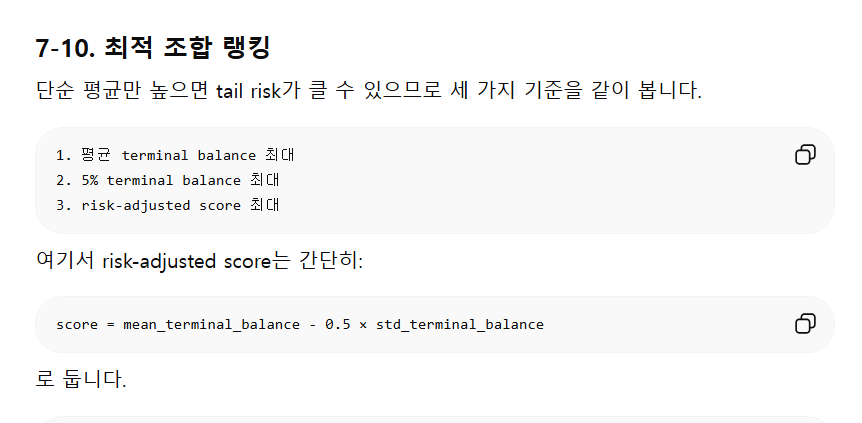

risk adusted score는 제외하고 해석하기로 함

In [32]:
# ============================================================
# 7-10. Ranking Optimal Hedge Combinations
# ============================================================

terminal_summary["risk_adjusted_score"] = (
    terminal_summary["mean_terminal_balance"]
    - 0.5 * terminal_summary["std_terminal_balance"]
)

rank_by_mean = terminal_summary.sort_values(
    "mean_terminal_balance",
    ascending=False
).reset_index(drop=True)

rank_by_p05 = terminal_summary.sort_values(
    "p05_terminal_balance",
    ascending=False
).reset_index(drop=True)



print("Top 10 by Mean Terminal Balance")
display(rank_by_mean.head(10))

print("Top 10 by 5% Terminal Balance")
display(rank_by_p05.head(10))



Top 10 by Mean Terminal Balance


,experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,principal_book_amount,hedge_book_amount,static_budget,dynamic_budget,mean_terminal_balance,std_terminal_balance,min_terminal_balance,p01_terminal_balance,p05_terminal_balance,p10_terminal_balance,p50_terminal_balance,p90_terminal_balance,p95_terminal_balance,max_terminal_balance,prob_negative_balance,prob_below_initial_notional,mean_principal_terminal,mean_static_terminal_account,mean_dynamic_terminal_account,mean_static_pnl,mean_dynamic_pnl,risk_adjusted_score
0,10,0.300000,0.700000,1.000000,0.000000,"3,000,000,000.000000","7,000,000,000.000000","7,000,000,000.000000",0.000000,"-430,721,955.181397","891,498,892.568358","-5,068,909,502.580158","-4,106,948,113.890548","-1,599,408,928.463153","-971,310,826.791570","-287,531,851.232797","-91,379,008.072872","-54,894,545.048269","4,310,591,071.536848",0.986700,1.000000,"-8,093,430,168.912080","7,662,708,213.730681",0.000000,"6,034,127.888236",0.000000,"-876,471,401.465576"
1,21,0.500000,0.500000,1.000000,0.000000,"5,000,000,000.000000","5,000,000,000.000000","5,000,000,000.000000",0.000000,"-432,225,666.474645","892,661,418.399981","-4,297,129,880.466564","-3,574,890,325.757631","-1,692,232,657.797280","-989,332,532.806974","-306,109,693.306799","-158,838,353.974045","-131,445,859.183190","5,518,091,514.757763",0.987000,1.000000,"-5,905,809,001.528523","5,473,583,335.053877",0.000000,"4,530,416.594987",0.000000,"-878,556,375.674636"
2,32,0.700000,0.300000,1.000000,0.000000,"7,000,000,000.000000","3,000,000,000.000000","3,000,000,000.000000",0.000000,"-434,037,833.112641","919,451,358.927305","-3,367,035,593.512827","-2,933,691,860.687467","-1,804,097,259.911256","-1,011,051,019.957728","-328,498,396.353452","-240,135,592.753800","-223,700,095.879287","6,973,285,758.754762",0.987000,1.000000,"-3,718,187,834.144968","3,284,150,001.032327",0.000000,"2,718,249.956992",0.000000,"-893,763,512.576293"
3,31,0.700000,0.300000,0.900000,0.100000,"7,000,000,000.000000","3,000,000,000.000000","2,700,000,000.000000","300,000,000.000000","-442,566,421.494655","926,723,122.429067","-3,243,555,703.812609","-2,851,356,251.748376","-1,836,131,446.200453","-1,028,564,110.967139","-341,413,122.969931","-254,505,235.742851","-236,143,950.727090","7,212,338,878.056069",0.987000,1.000000,"-3,718,187,834.144968","2,955,735,000.929094","319,886,411.721218","2,446,424.961293","654,795.966076","-905,927,982.709189"
4,20,0.500000,0.500000,0.900000,0.100000,"5,000,000,000.000000","5,000,000,000.000000","4,500,000,000.000000","500,000,000.000000","-446,548,555.032833","898,571,046.123686","-4,086,581,601.639235","-3,444,147,510.167003","-1,741,415,503.427895","-1,014,282,588.450345","-327,042,203.245620","-184,848,000.684177","-158,790,049.755647","5,896,723,018.890510",0.986600,1.000000,"-5,905,809,001.528523","4,926,225,001.548489","533,035,444.947200","4,077,374.935488","982,752.021963","-895,834,078.094676"
5,9,0.300000,0.700000,0.900000,0.100000,"3,000,000,000.000000","7,000,000,000.000000","6,300,000,000.000000","700,000,000.000000","-450,911,358.339028","892,121,769.303297","-4,787,124,301.109729","-3,935,658,106.274774","-1,663,880,839.357902","-1,001,590,216.689705","-315,658,935.787122","-128,877,140.119837","-95,129,365.554704","4,804,031,580.423425",0.984000,1.000000,"-8,093,430,168.912080","6,896,437,392.357615","746,081,418.215436","5,430,715.099412","1,207,648.120105","-896,972,242.990677"
6,30,0.700000,0.300000,0.800000,0.200000,"7,000,000,000.000000","3,000,000,000.000000","2,400,000,000.000000","600,000,000.000000","-451,095,009.876670","935,837,166.584620","-3,152,045,361.114426","-2,771,329,634.225189","-1,868,207,951.613168","-1,047,896,641.958904","-355,327,468.323282","-266,832,499.902580","-203,408,206.723753","7,451,391,997.357375",0.986300,1.000000,"-3,718,187,834.144968","2,627,320,000.825862","639,772,823.442436","2,174,599.965594","1,309,591.932152","-919,013,593.168980"
7,29,0.700000,0.300000,0.700000,0

Top 10 by 5% Terminal Balance


,experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,principal_book_amount,hedge_book_amount,static_budget,dynamic_budget,mean_terminal_balance,std_terminal_balance,min_terminal_balance,p01_terminal_balance,p05_terminal_balance,p10_terminal_balance,p50_terminal_balance,p90_terminal_balance,p95_terminal_balance,max_terminal_balance,prob_negative_balance,prob_below_initial_notional,mean_principal_terminal,mean_static_terminal_account,mean_dynamic_terminal_account,mean_static_pnl,mean_dynamic_pnl,risk_adjusted_score
0,10,0.300000,0.700000,1.000000,0.000000,"3,000,000,000.000000","7,000,000,000.000000","7,000,000,000.000000",0.000000,"-430,721,955.181397","891,498,892.568358","-5,068,909,502.580158","-4,106,948,113.890548","-1,599,408,928.463153","-971,310,826.791570","-287,531,851.232797","-91,379,008.072872","-54,894,545.048269","4,310,591,071.536848",0.986700,1.000000,"-8,093,430,168.912080","7,662,708,213.730681",0.000000,"6,034,127.888236",0.000000,"-876,471,401.465576"
1,9,0.300000,0.700000,0.900000,0.100000,"3,000,000,000.000000","7,000,000,000.000000","6,300,000,000.000000","700,000,000.000000","-450,911,358.339028","892,121,769.303297","-4,787,124,301.109729","-3,935,658,106.274774","-1,663,880,839.357902","-1,001,590,216.689705","-315,658,935.787122","-128,877,140.119837","-95,129,365.554704","4,804,031,580.423425",0.984000,1.000000,"-8,093,430,168.912080","6,896,437,392.357615","746,081,418.215436","5,430,715.099412","1,207,648.120105","-896,972,242.990677"
2,21,0.500000,0.500000,1.000000,0.000000,"5,000,000,000.000000","5,000,000,000.000000","5,000,000,000.000000",0.000000,"-432,225,666.474645","892,661,418.399981","-4,297,129,880.466564","-3,574,890,325.757631","-1,692,232,657.797280","-989,332,532.806974","-306,109,693.306799","-158,838,353.974045","-131,445,859.183190","5,518,091,514.757763",0.987000,1.000000,"-5,905,809,001.528523","5,473,583,335.053877",0.000000,"4,530,416.594987",0.000000,"-878,556,375.674636"
3,8,0.300000,0.700000,0.800000,0.200000,"3,000,000,000.000000","7,000,000,000.000000","5,600,000,000.000000","1,400,000,000.000000","-471,100,761.496661","899,661,122.937998","-4,505,339,099.639299","-3,754,766,452.774322","-1,728,632,570.434265","-1,088,850,488.634536","-341,428,705.009401","-164,226,514.177568","-98,521,763.142618","5,297,472,089.310001",0.973900,1.000000,"-8,093,430,168.912080","6,130,166,570.984546","1,492,162,836.430873","4,827,302.310589","2,415,296.240209","-920,931,322.965660"
4,20,0.500000,0.500000,0.900000,0.100000,"5,000,000,000.000000","5,000,000,000.000000","4,500,000,000.000000","500,000,000.000000","-446,548,555.032833","898,571,046.123686","-4,086,581,601.639235","-3,444,147,510.167003","-1,741,415,503.427895","-1,014,282,588.450345","-327,042,203.245620","-184,848,000.684177","-158,790,049.755647","5,896,723,018.890510",0.986600,1.000000,"-5,905,809,001.528523","4,926,225,001.548489","533,035,444.947200","4,077,374.935488","982,752.021963","-895,834,078.094676"
5,19,0.500000,0.500000,0.800000,0.200000,"5,000,000,000.000000","5,000,000,000.000000","4,000,000,000.000000","1,000,000,000.000000","-460,871,443.591021","908,725,201.327344","-3,912,083,008.973130","-3,307,841,999.713293","-1,791,006,102.776204","-1,058,767,952.082424","-346,640,711.939888","-209,548,211.646428","-143,760,753.930553","6,275,354,523.023255",0.981100,1.000000,"-5,905,809,001.528523","4,378,866,668.043101","1,066,070,889.894400","3,624,333.275990","1,965,504.043926","-915,234,044.254693"
6,7,0.300000,0.700000,0.700000,0.300000,"3,000,000,000.000000","7,000,000,000.000000","4,900,000,000.000000","2,100,000,000.000000","-491,290,164.654293","913,945,802.569415","-4,605,038,165.212899","-3,547,586,314.419285","-1,796,446,061.448593","-1,221,076,306.443871","-370,879,860.117585","-196,464,163.364724","-51,282,616.309036","5,790,912,598.196575",0.961900,1.000000,"-8,093,430,168.912080","5,363,895,749.611477","2,238,244,254.646309","4,223,889.521765","3,622,944.360314","-948,263,0

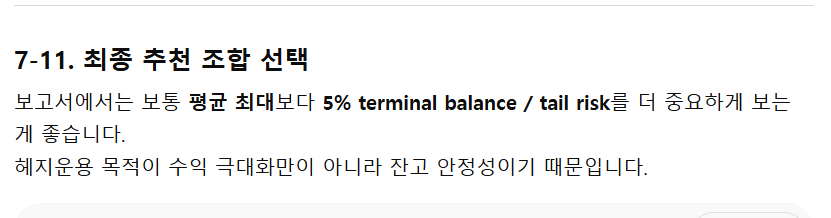

추천은 추천이고... 선배제시한 결과, 실무적합성 기준으로 선정하기

In [33]:
# ============================================================
# 7-11. Select Recommended Optimal Combination
# ============================================================

# 기본 추천 기준: 5% terminal balance가 가장 높은 조합
best_by_p05 = rank_by_p05.iloc[0]

best_experiment_id = int(best_by_p05["experiment_id"])

print("Recommended experiment ID:", best_experiment_id)
display(best_by_p05.to_frame().T)

Recommended experiment ID: 10


,experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,principal_book_amount,hedge_book_amount,static_budget,dynamic_budget,mean_terminal_balance,std_terminal_balance,min_terminal_balance,p01_terminal_balance,p05_terminal_balance,p10_terminal_balance,p50_terminal_balance,p90_terminal_balance,p95_terminal_balance,max_terminal_balance,prob_negative_balance,prob_below_initial_notional,mean_principal_terminal,mean_static_terminal_account,mean_dynamic_terminal_account,mean_static_pnl,mean_dynamic_pnl,risk_adjusted_score
0,10.000000,0.300000,0.700000,1.000000,0.000000,"3,000,000,000.000000","7,000,000,000.000000","7,000,000,000.000000",0.000000,"-430,721,955.181397","891,498,892.568358","-5,068,909,502.580158","-4,106,948,113.890548","-1,599,408,928.463153","-971,310,826.791570","-287,531,851.232797","-91,379,008.072872","-54,894,545.048269","4,310,591,071.536848",0.986700,1.000000,"-8,093,430,168.912080","7,662,708,213.730681",0.000000,"6,034,127.888236",0.000000,"-876,471,401.465576"


In [34]:
# ============================================================
# 7-11-1. Recommended Combination Pathwise Result
# ============================================================

best_terminal_balance = terminal_balance_matrix[best_experiment_id, :]

best_result_df = pd.DataFrame({
    "path_id": payoff_df["path_id"],
    "payoff_type": payoff_df["payoff_type"],
    "autocall_no": payoff_df["autocall_no"],
    "knock_in_occurred": payoff_df["knock_in_occurred"],
    "issuer_cash_outflow": payoff_df["issuer_cash_outflow"],
    "principal_terminal": principal_terminal_matrix[best_experiment_id, :],
    "static_terminal_account": static_terminal_account_matrix[best_experiment_id, :],
    "dynamic_terminal_account": dynamic_terminal_account_matrix[best_experiment_id, :],
    "terminal_balance": best_terminal_balance,
})

display(best_result_df.head())
display(best_result_df["terminal_balance"].describe())

,path_id,payoff_type,autocall_no,knock_in_occurred,issuer_cash_outflow,principal_terminal,static_terminal_account,dynamic_terminal_account,terminal_balance
0,0,autocall_1,1,False,"10,485,000,000.000000","-8,018,755,536.765878","7,510,172,038.021171",0.000000,"-508,583,498.744707"
1,1,autocall_1,1,False,"10,485,000,000.000000","-8,018,755,536.765878","7,988,208,877.325492",0.000000,"-30,546,659.440386"
2,2,autocall_1,1,False,"10,485,000,000.000000","-8,018,755,536.765878","7,844,755,164.071037",0.000000,"-174,000,372.694840"
3,3,autocall_1,1,False,"10,485,000,000.000000","-8,018,755,536.765878","7,486,272,019.382648",0.000000,"-532,483,517.383229"
4,4,autocall_1,1,False,"10,485,000,000.000000","-8,018,755,536.765878","7,543,212,053.668926",0.000000,"-475,543,483.096951"


count           10,000.000000
mean      -430,721,955.181397
std        891,498,892.568359
min     -5,068,909,502.580158
25%       -464,970,785.672867
50%       -287,531,851.232797
75%       -163,929,530.550688
max      4,310,591,071.536848
Name: terminal_balance, dtype: float64

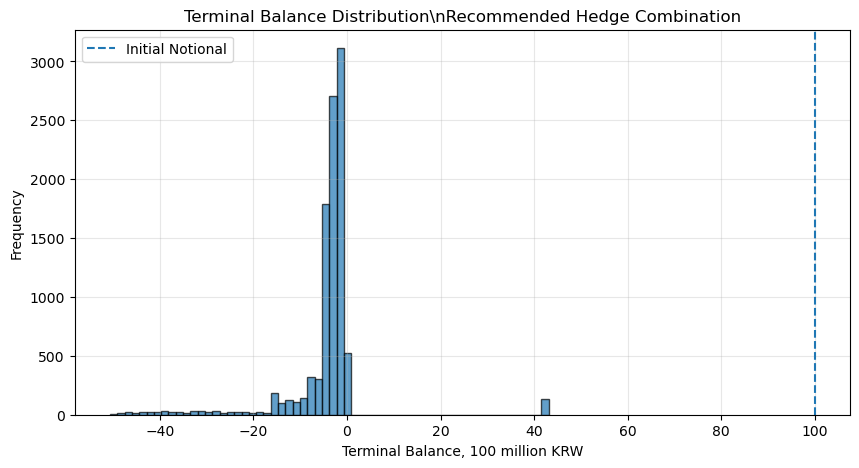

In [35]:
# ============================================================
# 7-12. Plot Terminal Balance Distribution of Best Combination
# ============================================================

plt.figure(figsize=(10, 5))
plt.hist(best_terminal_balance / 1e8, bins=60, edgecolor="black", alpha=0.7)
plt.axvline(NOTIONAL / 1e8, linestyle="--", label="Initial Notional")
plt.title("Terminal Balance Distribution\\nRecommended Hedge Combination")
plt.xlabel("Terminal Balance, 100 million KRW")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

원금북 비중별로 가장 좋은 정적/동적 조합을 만든다

In [36]:
# ============================================================
# 7-13. Best Combination by Principal Book Ratio
# ============================================================

best_by_principal_ratio = (
    terminal_summary
    .sort_values("p05_terminal_balance", ascending=False)
    .groupby("principal_book_ratio")
    .head(1)
    .sort_values("principal_book_ratio")
    .reset_index(drop=True)
)

best_by_principal_ratio

,experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,principal_book_amount,hedge_book_amount,static_budget,dynamic_budget,mean_terminal_balance,std_terminal_balance,min_terminal_balance,p01_terminal_balance,p05_terminal_balance,p10_terminal_balance,p50_terminal_balance,p90_terminal_balance,p95_terminal_balance,max_terminal_balance,prob_negative_balance,prob_below_initial_notional,mean_principal_terminal,mean_static_terminal_account,mean_dynamic_terminal_account,mean_static_pnl,mean_dynamic_pnl,risk_adjusted_score
0,10,0.300000,0.700000,1.000000,0.000000,"3,000,000,000.000000","7,000,000,000.000000","7,000,000,000.000000",0.000000,"-430,721,955.181397","891,498,892.568358","-5,068,909,502.580158","-4,106,948,113.890548","-1,599,408,928.463153","-971,310,826.791570","-287,531,851.232797","-91,379,008.072872","-54,894,545.048269","4,310,591,071.536848",0.986700,1.000000,"-8,093,430,168.912080","7,662,708,213.730681",0.000000,"6,034,127.888236",0.000000,"-876,471,401.465576"
1,21,0.500000,0.500000,1.000000,0.000000,"5,000,000,000.000000","5,000,000,000.000000","5,000,000,000.000000",0.000000,"-432,225,666.474645","892,661,418.399981","-4,297,129,880.466564","-3,574,890,325.757631","-1,692,232,657.797280","-989,332,532.806974","-306,109,693.306799","-158,838,353.974045","-131,445,859.183190","5,518,091,514.757763",0.987000,1.000000,"-5,905,809,001.528523","5,473,583,335.053877",0.000000,"4,530,416.594987",0.000000,"-878,556,375.674636"
2,32,0.700000,0.300000,1.000000,0.000000,"7,000,000,000.000000","3,000,000,000.000000","3,000,000,000.000000",0.000000,"-434,037,833.112641","919,451,358.927305","-3,367,035,593.512827","-2,933,691,860.687467","-1,804,097,259.911256","-1,011,051,019.957728","-328,498,396.353452","-240,135,592.753800","-223,700,095.879287","6,973,285,758.754762",0.987000,1.000000,"-3,718,187,834.144968","3,284,150,001.032327",0.000000,"2,718,249.956992",0.000000,"-893,763,512.576293"


In [37]:
# ============================================================
# 7-14. Pivot Tables for Heatmap
# ============================================================

pivot_mean = terminal_summary.pivot_table(
    index="principal_book_ratio",
    columns="static_ratio",
    values="mean_terminal_balance"
)

pivot_p05 = terminal_summary.pivot_table(
    index="principal_book_ratio",
    columns="static_ratio",
    values="p05_terminal_balance"
)

pivot_score = terminal_summary.pivot_table(
    index="principal_book_ratio",
    columns="static_ratio",
    values="risk_adjusted_score"
)

display(pivot_mean / 1e8)
display(pivot_p05 / 1e8)
display(pivot_score / 1e8)

static_ratio,0.000000,0.100000,0.200000,0.300000,0.400000,0.500000,0.600000,0.700000,0.800000,0.900000,1.000000
principal_book_ratio,,,,,,,,,,,
0.300000,-6.326160,-6.124266,-5.922372,-5.720478,-5.518584,-5.316690,-5.114796,-4.912902,-4.711008,-4.509114,-4.307220
0.500000,-5.754546,-5.611317,-5.468088,-5.324859,-5.181630,-5.038401,-4.895172,-4.751943,-4.608714,-4.465486,-4.322257
0.700000,-5.193237,-5.107951,-5.022665,-4.937380,-4.852094,-4.766808,-4.681522,-4.596236,-4.510950,-4.425664,-4.340378


static_ratio,0.000000,0.100000,0.200000,0.300000,0.400000,0.500000,0.600000,0.700000,0.800000,0.900000,1.000000
principal_book_ratio,,,,,,,,,,,
0.300000,-22.272191,-22.151854,-21.962655,-21.761858,-21.492092,-20.956464,-19.490657,-17.964461,-17.286326,-16.638808,-15.994089
0.500000,-21.661047,-21.484630,-21.148052,-20.695100,-20.284158,-19.620260,-18.904245,-18.403928,-17.910061,-17.414155,-16.922327
0.700000,-20.846256,-20.784422,-20.551664,-20.238090,-19.920247,-19.620375,-19.316606,-18.994610,-18.682080,-18.361314,-18.040973


static_ratio,0.000000,0.100000,0.200000,0.300000,0.400000,0.500000,0.600000,0.700000,0.800000,0.900000,1.000000
principal_book_ratio,,,,,,,,,,,
0.300000,-12.165222,-11.716881,-11.286138,-10.875338,-10.486996,-10.123727,-9.788129,-9.482631,-9.209313,-8.969722,-8.764714
0.500000,-11.349570,-11.023552,-10.709695,-10.409222,-10.123412,-9.853566,-9.600974,-9.366862,-9.152340,-8.958341,-8.785564
0.700000,-10.530402,-10.337755,-10.151517,-9.972075,-9.799816,-9.635125,-9.478379,-9.329937,-9.190136,-9.059280,-8.937635


In [38]:
# ============================================================
# 7-15. Heatmap Function
# ============================================================

def plot_heatmap(pivot_df, title, value_label):
    plt.figure(figsize=(12, 5))
    
    data = pivot_df.values / 1e8
    
    plt.imshow(data, aspect="auto")
    plt.colorbar(label=value_label)
    
    plt.xticks(
        ticks=np.arange(len(pivot_df.columns)),
        labels=[f"{x:.1f}" for x in pivot_df.columns]
    )
    
    plt.yticks(
        ticks=np.arange(len(pivot_df.index)),
        labels=[f"{x:.1f}" for x in pivot_df.index]
    )
    
    plt.xlabel("Static Hedge Ratio")
    plt.ylabel("Principal Book Ratio")
    plt.title(title)
    
    # 숫자 표시
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            plt.text(
                j,
                i,
                f"{data[i, j]:.1f}",
                ha="center",
                va="center",
                fontsize=8
            )
    
    plt.tight_layout()
    plt.show()

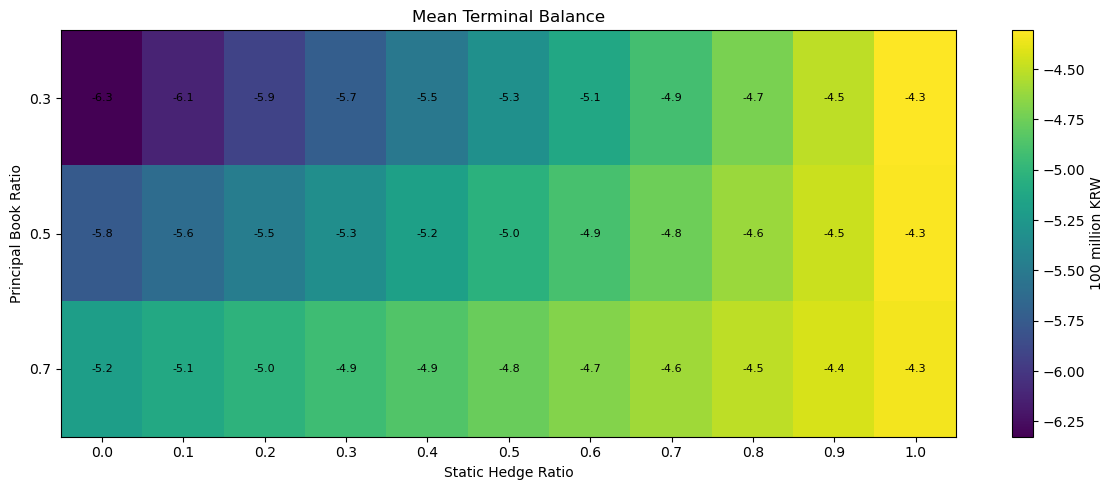

In [39]:
plot_heatmap(
    pivot_mean,
    title="Mean Terminal Balance",
    value_label="100 million KRW"
)

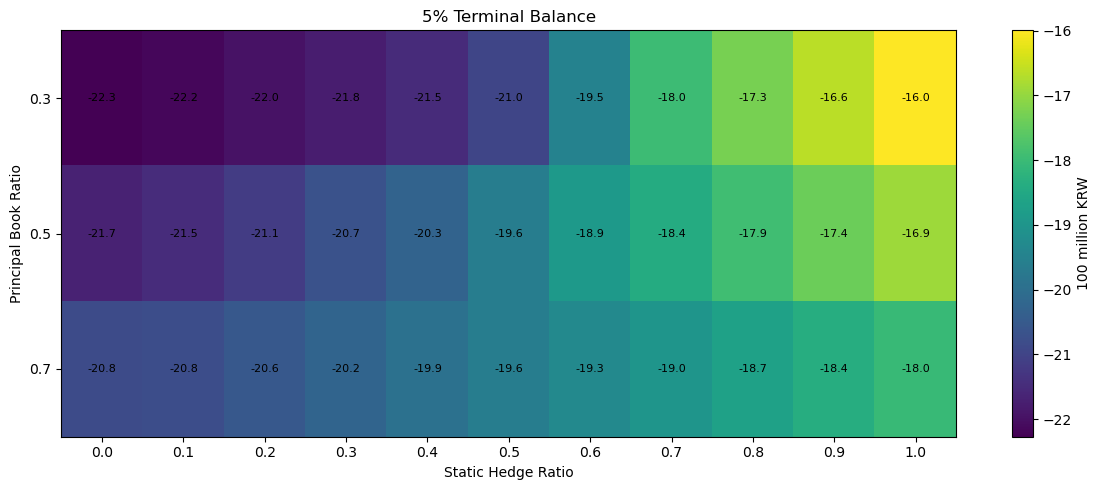

In [40]:
plot_heatmap(
    pivot_p05,
    title="5% Terminal Balance",
    value_label="100 million KRW"
)

In [42]:
# ============================================================
# 7-16. Terminal Balance by Payoff Type
# ============================================================

best_by_payoff_type = (
    best_result_df
    .groupby("payoff_type")
    .agg(
        count=("path_id", "count"),
        mean_terminal_balance=("terminal_balance", "mean"),
        min_terminal_balance=("terminal_balance", "min"),
        p05_terminal_balance=("terminal_balance", lambda x: np.percentile(x, 5)),
        p50_terminal_balance=("terminal_balance", "median"),
        mean_issuer_cash_outflow=("issuer_cash_outflow", "mean"),
        mean_principal_terminal=("principal_terminal", "mean"),
        mean_static_terminal_account=("static_terminal_account", "mean"),
        mean_dynamic_terminal_account=("dynamic_terminal_account", "mean"),
    )
    .reset_index()
)

best_by_payoff_type["probability"] = best_by_payoff_type["count"] / len(best_result_df)

best_by_payoff_type

,payoff_type,count,mean_terminal_balance,min_terminal_balance,p05_terminal_balance,p50_terminal_balance,mean_issuer_cash_outflow,mean_principal_terminal,mean_static_terminal_account,mean_dynamic_terminal_account,probability
0,autocall_1,8038,"-256,510,127.703235","-539,559,389.504504","-493,793,059.490466","-241,395,598.760951","10,485,000,000.000000","-8,018,755,536.765878","7,762,245,409.062643",0.000000,0.803800
1,autocall_2,607,"-631,703,656.561111","-799,374,791.386317","-782,094,385.732957","-642,547,919.370274","10,970,000,000.000000","-8,366,886,444.186008","7,735,182,787.624899",0.000000,0.060700
2,autocall_3,272,"-876,092,721.470131","-1,031,723,520.741370","-1,018,755,522.570752","-885,981,139.759604","11,455,000,000.000000","-8,700,302,836.526306","7,824,210,115.056175",0.000000,0.027200
3,autocall_4,202,"-1,178,220,051.464480","-1,337,758,921.391140","-1,320,858,410.401154","-1,182,619,720.430865","11,940,000,000.000000","-9,022,180,216.315247","7,843,960,164.850767",0.000000,0.020200
4,autocall_5,164,"-1,425,847,110.935485","-1,595,554,089.657307","-1,579,125,874.311386","-1,411,936,630.853740","12,425,000,000.000000","-9,329,785,462.653004","7,903,938,351.717519",0.000000,0.016400
5,autocall_6,129,"-1,599,408,928.463153","-1,599,408,928.463153","-1,599,408,928.463153","-1,599,408,928.463153","12,910,000,000.000000","-9,628,568,248.924665","8,029,159,320.461513",0.000000,0.012900
6,maturity_knock_in_loss,130,"4,310,591,071.536846","4,310,591,071.536846","4,310,591,071.536846","4,310,591,071.536846","3,510,873,749.160325","-229,441,998.084991","4,540,033,069.621838",0.000000,0.013000
7,maturity_no_knock_in,458,"-3,287,911,608.082313","-5,068,909,502.580158","-4,656,410,124.224526","-3,261,093,728.650640","12,910,000,000.000000","-9,628,568,248.924665","6,340,656,640.842352",0.000000,0.045800


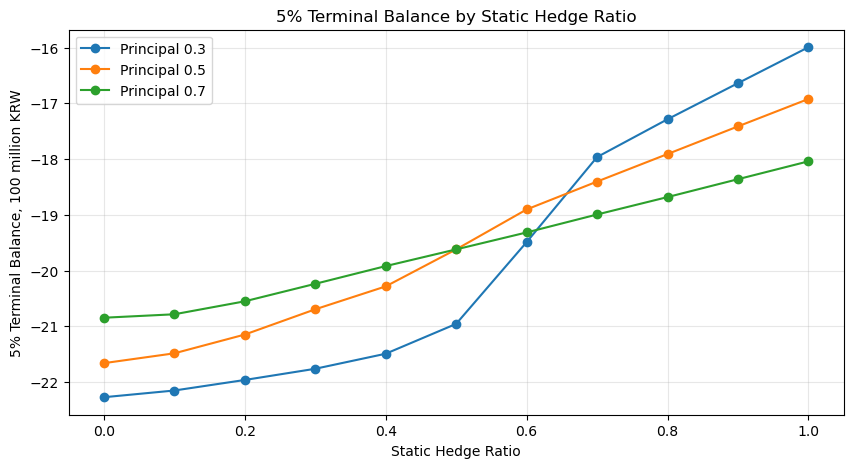

In [46]:
# ============================================================
# 7-17. Compare Static Ratio and Terminal Balance
# ============================================================

plt.figure(figsize=(10, 5))

for principal_ratio in sorted(terminal_summary["principal_book_ratio"].unique()):
    temp = terminal_summary[
        terminal_summary["principal_book_ratio"] == principal_ratio
    ].sort_values("static_ratio")
    
    plt.plot(
        temp["static_ratio"],
        temp["p05_terminal_balance"] / 1e8,
        marker="o",
        label=f"Principal {principal_ratio:.1f}"
    )

plt.title("5% Terminal Balance by Static Hedge Ratio")
plt.xlabel("Static Hedge Ratio")
plt.ylabel("5% Terminal Balance, 100 million KRW")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

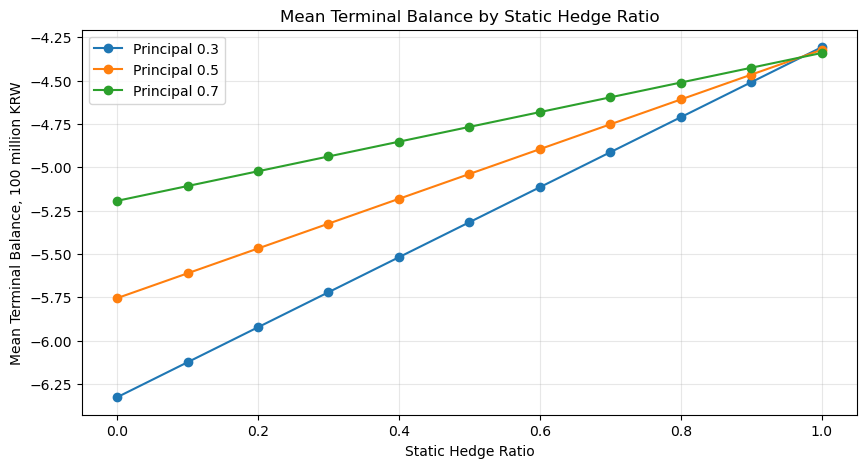

In [49]:
plt.figure(figsize=(10, 5))

for principal_ratio in sorted(terminal_summary["principal_book_ratio"].unique()):
    temp = terminal_summary[
        terminal_summary["principal_book_ratio"] == principal_ratio
    ].sort_values("static_ratio")
    
    plt.plot(
        temp["static_ratio"],
        temp["mean_terminal_balance"] / 1e8,
        marker="o",
        label=f"Principal {principal_ratio:.1f}"
    )

plt.title("Mean Terminal Balance by Static Hedge Ratio")
plt.xlabel("Static Hedge Ratio")
plt.ylabel("Mean Terminal Balance, 100 million KRW")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# ============================================================
# 7-18. Save Section 7 Outputs
# ============================================================

np.save(
    OUTPUT_DIR / "terminal_balance_matrix.npy",
    terminal_balance_matrix
)

np.save(
    OUTPUT_DIR / "principal_terminal_matrix.npy",
    principal_terminal_matrix
)

np.save(
    OUTPUT_DIR / "static_terminal_account_matrix.npy",
    static_terminal_account_matrix
)

terminal_summary_path = OUTPUT_DIR / "terminal_balance_summary.csv"
rank_by_mean_path = OUTPUT_DIR / "rank_by_mean_terminal_balance.csv"
rank_by_p05_path = OUTPUT_DIR / "rank_by_p05_terminal_balance.csv"
rank_by_score_path = OUTPUT_DIR / "rank_by_risk_adjusted_score.csv"
best_result_path = OUTPUT_DIR / "best_experiment_pathwise_result.csv"
best_by_payoff_type_path = OUTPUT_DIR / "best_experiment_by_payoff_type.csv"
best_by_principal_ratio_path = OUTPUT_DIR / "best_by_principal_book_ratio.csv"

terminal_summary.to_csv(
    terminal_summary_path,
    index=False,
    encoding="utf-8-sig"
)

rank_by_mean.to_csv(
    rank_by_mean_path,
    index=False,
    encoding="utf-8-sig"
)

rank_by_p05.to_csv(
    rank_by_p05_path,
    index=False,
    encoding="utf-8-sig"
)



best_result_df.to_csv(
    best_result_path,
    index=False,
    encoding="utf-8-sig"
)

best_by_payoff_type.to_csv(
    best_by_payoff_type_path,
    index=False,
    encoding="utf-8-sig"
)

best_by_principal_ratio.to_csv(
    best_by_principal_ratio_path,
    index=False,
    encoding="utf-8-sig"
)

print("Saved terminal balance matrix")
print("Saved terminal summary to:", terminal_summary_path)
print("Saved ranking by mean to:", rank_by_mean_path)
print("Saved ranking by p05 to:", rank_by_p05_path)
print("Saved ranking by score to:", rank_by_score_path)
print("Saved best pathwise result to:", best_result_path)
print("Saved best payoff type summary to:", best_by_payoff_type_path)
print("Saved best by principal ratio to:", best_by_principal_ratio_path)

Saved terminal balance matrix
Saved terminal summary to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output\terminal_balance_summary.csv
Saved ranking by mean to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output\rank_by_mean_terminal_balance.csv
Saved ranking by p05 to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output\rank_by_p05_terminal_balance.csv
Saved ranking by score to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output\rank_by_risk_adjusted_score.csv
Saved best pathwise result to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output\best_experiment_pathwise_result.csv
Saved best payoff type summary to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output\best_experiment_by_payoff_type.csv
Saved best by principal ratio to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output\best_by_principal_book_ratio.csv
